In [ ]:
import numpy as np
array = np.array([[[[1,2,3,4],
                  [5,6,7,8],
                  [9,10,11,12],
                  [13,14,15,16]]]])


In [ ]:
import numpy as np
#print(np.__version__)
'''
my_list = [1,2,3,4]

my_list = my_list * 2
print(my_list)

array = np.array([1,2,3,4])
array = array * 2
print(array)
'''
#multi dimensional

array = np.array([['A','B','C'],['D','E','F'],['G','H','I']])
print(array.ndim)
print(array.shape)
print(array[0:])

print(array[0][2])

#multi dimensional indexing
print(array[0,2])

word = array[0,0] + array[2,1]+ array[2,1]
print(word)

#slicing using numpy
array = np.array([[1,2,3,4],
                  [5,6,7,8],
                  [9,10,11,12],
                  [13,14,15,16]])

#array[start:end:step]
print(array[0])
print(array[0:3])

print(array[:,0])

2
(3, 3)
[['A' 'B' 'C']
 ['D' 'E' 'F']
 ['G' 'H' 'I']]
C
C
AHH
[1 2 3 4]
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
[ 1  5  9 13]


In [ ]:
array = np.array([[1,2,3,4],
                  [5,6,7,8],
                  [9,10,11,12],
                  [13,14,15,16]])

print(array[1:4:2,3])

[ 8 16]


In [ ]:
print(array[0:2,:2])

[[1 2]
 [5 6]]


In [ ]:
print(array[0:].shape)

(4, 4)


In [ ]:
array.mean(axis=0)

array([ 7.,  8.,  9., 10.])

In [ ]:
sales = np.array([243.50, 1820.00, 14.62, 957.58, 2800.00,
                  115.96,  407.52,   3.99, 1297.58,  522.44])
print(sales.shape)

(10,)


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

url = 'https://raw.githubusercontent.com/sumit0072/Superstore-Data-Analysis/main/Sample%20-%20Superstore.csv'
df = pd.read_csv(url, encoding='latin1')
sales =  df['Sales'].values
print(f"Loaded {len(sales):,}orders. Lets analyse them statistically.")


Loaded 9,994orders. Lets analyse them statistically.


In [ ]:
df.head(5)
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [ ]:
print("SUPERSTORE SALES - STATISTICAL REPORT")
print("=" * 42)

print(f"Total orders:     {len(sales):>10,}")
print(f"Mean sale:        ${sales.mean():>10,.2f}")
print(f"Median sale:      ${np.median(sales):>10,.2f}")
print(f"Std deviation:    ${sales.std():>10,.2f}")  # Std Dev measures how SPREAD OUT the values are around the mean
print(f"Min:              ${sales.min():>10,.2f}")
print(f"Max:              ${sales.max():>10,.2f}")
print(f"25th percentile:  ${np.percentile(sales, 25):>10,.2f}")
print(f"75th percentile:  ${np.percentile(sales, 75):>10,.2f}")
print(f"IQR:              ${np.percentile(sales, 75) - np.percentile(sales, 25):>10,.2f}")  #Inter Quartile Range
print(f"Skewness:         {stats.skew(sales):>10.3f}")

print("=" * 42)

diff = sales.mean() - np.median(sales)

print(f"\nMean is ${diff:.0f} ABOVE median → right-skewed")
print("A few very large orders pull the mean up.")
print(f"The MEDIAN (${np.median(sales):.0f}) is more representative.")

SUPERSTORE SALES - STATISTICAL REPORT
Total orders:             10
Mean sale:        $    818.32
Median sale:      $    464.98
Std deviation:    $    869.98
Min:              $      3.99
Max:              $  2,800.00
25th percentile:  $    147.84
75th percentile:  $  1,212.58
IQR:              $  1,064.73
Skewness:              1.095

Mean is $353 ABOVE median → right-skewed
A few very large orders pull the mean up.
The MEDIAN ($465) is more representative.


In [ ]:
from scipy import stats

print("USE 1 - Z-SCORE FOR OUTLIER DETECTION")
print("=" * 42)
print("Rule: if |z-score| > 3 → OUTLIER")
print("Why? Only 0.3% of normal data has |z| > 3\n")

z_scores = np.abs(stats.zscore(sales))
is_outlier = z_scores > 3
n_outliers = is_outlier.sum()

print(f"Total orders:      {len(sales):,}")
print(f"Outliers (|z|>3):  {n_outliers:,} ({n_outliers/len(sales)*100:.1f}%)")
print(f"Normal orders:     {(~is_outlier).sum():,}")

print(f"\nTop 5 outlier values:")
outlier_vals = sales[is_outlier]

for v in sorted(outlier_vals, reverse=True)[:5]:
    z = abs((v - sales.mean()) / sales.std())
    print(f"  Sale: ${v:>10,.2f} | z-score: {z:.1f}")

# IQR method comparison
Q1 = np.percentile(sales, 25)
Q3 = np.percentile(sales, 75)
IQR = Q3 - Q1

iqr_outliers = (
    ((sales < Q1 - 1.5 * IQR) | (sales > Q3 + 1.5 * IQR))
).sum()

print(f"\nZ-score outliers: {n_outliers}")
print(f"IQR outliers:     {iqr_outliers}")
print(f"\nFor SKEWED data like sales → use IQR (more appropriate)")
print(f"For NORMAL data like heights → use Z-score")

USE 1 - Z-SCORE FOR OUTLIER DETECTION
Rule: if |z-score| > 3 → OUTLIER
Why? Only 0.3% of normal data has |z| > 3

Total orders:      10
Outliers (|z|>3):  0 (0.0%)
Normal orders:     10

Top 5 outlier values:

Z-score outliers: 0
IQR outliers:     0

For SKEWED data like sales → use IQR (more appropriate)
For NORMAL data like heights → use Z-score


In [ ]:
#Assignment tasks
'''Statistical Audit of Superstore Profit column

Using df already loaded:

1. Print all descriptive stats for Profit
   (mean, median, std, min, max, Q1, Q3, IQR, skewness)

2. Answer:
   - How many orders had NEGATIVE profit (losses)?
   - What % of total orders were losses?
   - Total $ lost on loss-making orders?

3. Outlier detection — BOTH methods:
   - Z-score (|z| > 3): how many outliers?
   - IQR method: how many outliers?
   - Which finds more? Print the reason.

4. Hypothesis test:
   "Is Furniture profit significantly LOWER than store average?"
   Print: z-stat, p-value, conclusion'''

'Statistical Audit of Superstore Profit column\n\nUsing df already loaded:\n\n1. Print all descriptive stats for Profit\n   (mean, median, std, min, max, Q1, Q3, IQR, skewness)\n\n2. Answer:\n   - How many orders had NEGATIVE profit (losses)?\n   - What % of total orders were losses?\n   - Total $ lost on loss-making orders?\n\n3. Outlier detection — BOTH methods:\n   - Z-score (|z| > 3): how many outliers?\n   - IQR method: how many outliers?\n   - Which finds more? Print the reason.\n\n4. Hypothesis test:\n   "Is Furniture profit significantly LOWER than store average?"\n   Print: z-stat, p-value, conclusion'

In [ ]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [ ]:
#Task 1
mean     = df['Profit'].mean()
median   = df['Profit'].median()
std      = df['Profit'].std()
Q1       = df['Profit'].quantile(0.25)
Q3       = df['Profit'].quantile(0.75)
IQR      = Q3 - Q1
skewness = df['Profit'].skew()
min_val  = df['Profit'].min()
max_val  = df['Profit'].max()

print("="*40)
print("Task 1:Descriptive Statistics: Profit")
print("="*40)
print(f"{'Mean':<20}: {mean:>10.2f}")
print(f"{'Median':<20}: {median:>10.2f}")
print(f"{'Std Dev':<20}: {std:>10.2f}")
print(f"{'Min':<20}: {min_val:>10.2f}")
print(f"{'Max':<20}: {max_val:>10.2f}")
print(f"{'Q1 (25th pct)':<20}: {Q1:>10.2f}")
print(f"{'Q3 (75th pct)':<20}: {Q3:>10.2f}")
print(f"{'IQR':<20}: {IQR:>10.2f}")
print(f"{'Skewness':<20}: {skewness:>10.2f}")
print("="*40)

Task 1:Descriptive Statistics: Profit
Mean                :      28.66
Median              :       8.67
Std Dev             :     234.26
Min                 :   -6599.98
Max                 :    8399.98
Q1 (25th pct)       :       1.73
Q3 (75th pct)       :      29.36
IQR                 :      27.64
Skewness            :       7.56


In [ ]:
#Task 2
loss_rows = df['Profit'] < 0
losses_df = df[loss_rows]

print(losses_df['Profit'])
count_of_losses = loss_rows.sum()
total_orders = df.shape[0]

pct_losses = (count_of_losses / total_orders) * 100
total_loss = losses_df['Profit'].sum()

print("="*40)
print("Task 2:Loss-Making Orders Summary")
print("="*40)
print(f"{'Count of Losses':<20}: {count_of_losses:>10}")
print(f"{'Total Orders':<20}: {total_orders:>10}")
print(f"{'% Losses':<20}: {pct_losses:>9.2f}%")
print(f"{'Total $ Lost':<20}: {total_loss:>10.2f}")
print("="*40)

3       -383.0310
14      -123.8580
15        -3.8160
23        -1.0196
27     -1665.0522
          ...    
9920     -35.8176
9921      -4.5936
9931     -40.1960
9937      -1.7772
9962     -67.6704
Name: Profit, Length: 1871, dtype: float64
Task 2:Loss-Making Orders Summary
Count of Losses     :       1871
Total Orders        :       9994
% Losses            :     18.72%
Total $ Lost        : -156131.29


In [ ]:
z_scores       = ((df['Profit'] - mean )/std).abs()
outliers       =  z_scores > 3
outliers_count = outliers.sum()

IQR_outliers = ((df['Profit'] < Q1 - 1.5 * IQR) | (df['Profit'] > Q3 + 1.5 * IQR)).sum()

print("="*40)
print("Task 3:Outlier Detection: Profit")
print("="*40)
print(f"{'Z-score outliers (|z|>3)':<28}: {outliers_count:>10}")
print(f"{'IQR outliers':<28}: {IQR_outliers:>10}")
print("="*40)

Task 3:Outlier Detection: Profit
Z-score outliers (|z|>3)    :        107
IQR outliers                :       1881


In [ ]:
#Task 4
furniture   = df[df['Category'] =='Furniture']
mean_profit = furniture['Profit'].mean()
n_furniture = len(furniture)
n           = np.sqrt(n_furniture)
z_stat = (mean_profit - mean)/(std/n)
#p-value yet to be calculated

##Day 5
###Load + First Commands

In [ ]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/sumit0072/Superstore-Data-Analysis/main/Sample%20-%20Superstore.csv"
df = pd.read_csv(url, encoding='latin-1')

# THE 5 COMMANDS YOU RUN ON EVERY NEW DATASET

print("1. Shape (rows, columns):")
print(df.shape)

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. Data types:")
print(df.dtypes)

print("\n4. First 5 rows:")
print(df.head())

print("\n5. Statistical summary:")
print(df.describe().round(2))

print("\n6. Missing values:")
missing = df.isnull().sum()
print(missing[missing > 0])
if missing.sum() == 0:
    print("No missing values!")


1. Shape (rows, columns):
(9994, 21)

2. Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

3. Data types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

4. First 5 rows:
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/

In [ ]:
#--SELECT COLUMNS ----------------------
one_col  = df['Sales']              #Series - one column
two_cols = df[['Sales','Profit']]   #Dataframe - multiple columns

print(f"Type of on_col: {type(one_col)}")
print(f"Type of two_cols: {type(two_cols)}")

#--FILTER ROWS -------------------------
high_sales = df[df['Sales'] > 5000]
loss_orders = df[df['Profit'] < 0]
technology  = df[df['Category'] == 'Technology']

print(f"\nOrders > $5,000:    {len(high_sales):,}")
print(f"\nLoss-making orders: {len(loss_orders):,} ({len(loss_orders)/len(df)*100:.1f}%)")
print(f"Technology orders:    {len(technology):,}")


# Multiple conditions - & means AND, | means OR, ~ means NOT

profit_tech = df[(df["Category"] == "Technology") & (df["Profit"] > 0)]
heavy_disc = df[df["Discount"] >= 0.40]
not_south = df[~df["Region"].isin(["South"])]


print(f"\nProfitable tech: {len(profit_tech):,}")
print(f"Heavy discount (40%+): {len(heavy_disc):,}")
print(f"Not South region: {len(not_south):,}")


# isin - filter by list of values

key_cats = df[df["Category"].isin(["Technology", "Office Supplies"])]
print(f"\nTech + Office Supplies: {len(key_cats):,}")

Type of on_col: <class 'pandas.core.series.Series'>
Type of two_cols: <class 'pandas.core.frame.DataFrame'>

Orders > $5,000:    19

Loss-making orders: 1,871 (18.7%)
Technology orders:    1,847

Profitable tech: 1,573
Heavy discount (40%+): 1,139
Not South region: 8,374

Tech + Office Supplies: 7,873


###loc + iloc + sorting

In [ ]:
#SORTING

print("Top 5 orders by Sales:")
top5 = df.nlargest(5, "Sales")[["Customer Name", "Category", "Sales", "Profit"]]   # we have to pass the columns as a list
print(top5.to_string(index=False))
print("\nto_string without index = false")
print(top5.to_string)
print("\nTop 5 biggest losses:")
worst = df.nsmallest(5, "Profit")[["Customer Name", "Category", "Sales", "Profit"]]
print(worst.to_string(index=False))


# loc - label-based (use column NAMES)

print(f"\nloc - row 2, Sales column: {df.loc[2, 'Sales']}")
print("loc - rows 0-2, select cols:")
print(df.loc[0:2, ["Customer Name", "Category", "Sales"]])   #loc is inclusive


# iloc - position-based (use NUMBERS)

print(f"\niloc - row 2, col 3: {df.iloc[2, 3]}")
print("iloc - first 2 rows, first 3 cols:")
print(df.iloc[:2, :3])       #iloc is exclusive


print("""
RULE:
    loc  = by LABEL (column names, index labels)
    iloc = by POSITION (0, 1, 2, 3...)

Use loc when you know names. iloc when you know positions.
""")

Top 5 orders by Sales:
Customer Name   Category     Sales     Profit
  Sean Miller Technology 22638.480 -1811.0784
 Tamara Chand Technology 17499.950  8399.9760
 Raymond Buch Technology 13999.960  6719.9808
 Tom Ashbrook Technology 11199.968  3919.9888
 Hunter Lopez Technology 10499.970  5039.9856

to_string without index = false
<bound method DataFrame.to_string of      Customer Name    Category      Sales     Profit
2697   Sean Miller  Technology  22638.480 -1811.0784
6826  Tamara Chand  Technology  17499.950  8399.9760
8153  Raymond Buch  Technology  13999.960  6719.9808
2623  Tom Ashbrook  Technology  11199.968  3919.9888
4190  Hunter Lopez  Technology  10499.970  5039.9856>

Top 5 biggest losses:
 Customer Name        Category    Sales     Profit
 Cindy Stewart      Technology 4499.985 -6599.9780
Grant Thornton      Technology 7999.980 -3839.9904
   Luke Foster Office Supplies 2177.584 -3701.8928
Sharelle Roach      Technology 2549.985 -3399.9800
 Henry Goldwyn Office Supplies 188

###Missing values

In [ ]:
#Create a messy sample to demonstrate
import pandas as pd
import numpy as np
messy = pd.DataFrame({
    "name":   ["Alice", "Bob", None,    "Diana",  "Eve"],
    "sales":  [1200,    None,  890,     1500,     None],
    "region": ["East",  "West","East",  None,     "West"],
    "score":  [4.5,     3.2,   None,    4.1,      3.8],
})

print("Messy Data:");print(messy)
print(f"\nMissing counts:\n{messy.isnull().sum()}")

#Strategy 1 : Drop rows with ANY missing value
print(f"\nAfter dropna(): {len(messy.dropna())} rows remain")

#Strategy 2: Drop only if specific column is missing
print(f"After dropna(subset=['sales]): {len(messy.dropna(subset=['sales']))} rows")

#Strategy 3: Fill with mean/median
mean_sales    = messy['sales'].mean()
median_sales  = messy['sales'].median()
filled_mean   = messy['sales'].fillna(mean_sales)
filled_median = messy['sales'].fillna(median_sales)
print(f"\nMean: {mean_sales:.0f}, Median: {median_sales:.0f}")
print(f"Filled with median: {filled_median.values}")

#Strategy 4: Fill categorical with mode
mode_region = messy['region'].mode()[0]
filled_reg  = messy['region'].fillna(mode_region)
print(f"Filled region with mode  '{mode_region}' : {filled_reg.values}")


print('''
WHICH STRATEGY?
  dropna()                 -->Use when few rows missing and data is random
  fillna(median)           -->Use for NUMBERS when data is skewed
  fillna(mean)             -->Use for NUMBERS when data is symmetric
  fillna(mode)             -->Use for CATEGORIES
  fillna(method = 'ffill)  -->Use for TIME SERIES''')

Messy Data:
    name   sales region  score
0  Alice  1200.0   East    4.5
1    Bob     NaN   West    3.2
2   None   890.0   East    NaN
3  Diana  1500.0   None    4.1
4    Eve     NaN   West    3.8

Missing counts:
name      1
sales     2
region    1
score     1
dtype: int64

After dropna(): 1 rows remain
After dropna(subset=['sales]): 3 rows

Mean: 1197, Median: 1200
Filled with median: [1200. 1200.  890. 1500. 1200.]
Filled region with mode  'East' : ['East' 'West' 'East' 'East' 'West']

WHICH STRATEGY?
  dropna()                 -->Use when few rows missing and data is random
  fillna(median)           -->Use for NUMBERS when data is skewed
  fillna(mean)             -->Use for NUMBERS when data is symmetric
  fillna(mode)             -->Use for CATEGORIES
  fillna(method = 'ffill)  -->Use for TIME SERIES


In [ ]:
''' Assignment 1
Use the Superstore df — answer these business questions:
First look: run all 5 commands. Note 2 things that surprised you.Filtering:
a) How many orders have discount of 50% or more?
b) How many orders are in the "West" AND have profit > 0?
c) Which 3 sub-categories appear most often in loss orders?Sorting:
a) Top 10 customers by Sales amount
b) Bottom 5 states by profitCreate a new column "Is_Profitable" (True if Profit > 0)
What % of all orders are profitable?Create a column "Discount_Category":
"None" if Discount == 0
"Low" if 0 < Discount < 0.2
"Medium" if 0.2 <= Discount < 0.4
"Heavy" if Discount >= 0.4
Count orders in each category.
 Assignment 2

Find all "Furniture" orders with Profit < -100.
What do they have in common? (Check Discount and Sub-Category)Create a column: profit_per_unit = Profit / Quantity
Which Sub-Category has the best and worst profit per unit?Filter to only "Technology" orders.
What is the mean, median, and std of Technology sales?
Is Technology more or less variable than overall?CHALLENGE: Find customers who have placed orders in MULTIPLE regions.
Hint: groupby + nunique()'''

In [ ]:

#Assignment 1
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/sumit0072/Superstore-Data-Analysis/main/Sample%20-%20Superstore.csv"
df = pd.read_csv(url, encoding='latin-1')

print("1. Shape (rows, columns):")
print(df.shape)

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. Data types:")
print(df.dtypes)

print("\n4. First 5 rows:")
print(df.head())

print("\n5. Statistical summary:")
print(df.describe().round(2))

print("\n6. Missing values:")
missing = df.isnull().sum()
print(missing[missing > 0])
if missing.sum() == 0:
    print("No missing values!")

#a)
discount_orders = df['Discount'] >= 0.50
print(f"Number of orders which have discount of 50% of more :{discount_orders.sum()}")

#b)
orders_w = (df['Region'] == 'West') & (df['Profit'] > 0)
print(f"Number of orders which are in the West region and have positive profit are: {orders_w.sum()} ")

#c)
losses = df[df['Profit'] < 0]                          # step 1: filter to loss-making orders only
top_loss_subs = losses['Sub-Category'].value_counts().head(3)  # step 2: count occurrences per sub-category, keep top 3
print(top_loss_subs)

#2 Sorting
#a)Top10 customers by individual sale amount
top_10_orders  = df.nlargest(10, "Sales")[["Customer Name", "Sales"]]
print(f"Top 10 customers by individual top sales:   {top_10_orders.to_string(index=False)}")

#Top 10 sales by customers
top_10 = df.groupby('Customer Name')['Sales'].sum().sort_values(ascending=False).head(10)
print(top_10)

#b)Bottom by statest by individual profit
bottom5_orders = df.nsmallest(5, "Profit")[["Customer Name", "State", "Category", "Profit"]]
print(bottom5_orders.to_string(index=False))

#Bottom  5 individual orders with the worst profit
bot_5 = df.groupby('State')['Profit'].sum().sort_values().head(5)
print(bot_5)

#4)Create a new column "Is_Profitable" (True if Profit > 0)
#What % of all orders are profitable?
df['Is_Profitable'] = df['Profit'] > 0
percent_orders =  df['Is_Profitable'].mean()*100
print(f"{percent_orders:.2f}% of orders are profitable")

#5)Create a column "Discount_Category":
'''    "None" if Discount == 0
    "Low" if 0 < Discount < 0.2
    "Medium" if 0.2 <= Discount < 0.4
    "Heavy" if Discount >= 0.4
    Count orders in each category.'''
def categorize_discount(discount):
    if discount == 0:
        return "None"
    elif discount < 0.2:
        return "Low"
    elif discount < 0.4:
        return "Medium"
    else:
        return "Heavy"

df["Discount_Category"] = df["Discount"].apply(categorize_discount)

print(f"Discount category column contains : {df["Discount_Category"].value_counts()}")

#Assignment 2
#1)Find all "Furniture" orders with Profit < -100.
#What do they have in common? (Check Discount and Sub-Category)
bad_furniture = df[(df["Category"] == "Furniture") & (df["Profit"] < -100)]

print(f"Discount values counts for bad furniture with less than -100 profit: {bad_furniture["Discount"].value_counts()}")
print(f"Value counts for sub category with less than -100 profit{bad_furniture["Sub-Category"].value_counts()}")

#2)Create a column: profit_per_unit = Profit / Quantity
#Which Sub-Category has the best and worst profit per unit?
df["profit_per_unit"] = df["Profit"] / df["Quantity"]

per_subcat = df.groupby("Sub-Category")["profit_per_unit"].mean().sort_values()
print("Worst:", per_subcat.head(1))
print("Best:", per_subcat.tail(1))

#3) Filter to only "Technology" orders.
#What is the mean, median, and std of Technology sales?
#Is Technology more or less variable than overall?
technology = df[df["Category"] == 'Technology' ]

tech_mean   = technology["Sales"].mean()
tech_median = technology["Sales"].median()
tech_std    = technology["Sales"].std()

overall_std = df["Sales"].std()
print(f"Tech — mean: {tech_mean:.2f}, median: {tech_median:.2f}, std: {tech_std:.2f}")
print(f"Overall std: {overall_std:.2f}")

#Technology sales are notably more variable than the store's overall sales (std : 1108.66 vs 623.25),
#driven by a right-skewed mix of many low-value orders and a few very large ones

#CHALLENGE: Find customers who have placed orders in MULTIPLE regions.
#Hint: groupby + nunique()
cust_reg  = df.groupby('Customer Name')["Region"].nunique()
multi_regon_cust  =  cust_reg[cust_reg > 1]

print(f"Customers active in multiple regions: {len(multi_regon_cust)}")
print(multi_regon_cust.head())




1. Shape (rows, columns):
(9994, 21)

2. Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

3. Data types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

4. First 5 rows:
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/

In [ ]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

##Day 5


*   Pandas Advanced -  GroupBy + Feature Engineering



In [ ]:
#GroupBy basics
import pandas as pd
url = "https://raw.githubusercontent.com/sumit0072/Superstore-Data-Analysis/main/Sample%20-%20Superstore.csv"
df = pd.read_csv(url, encoding='latin-1')

#Single column groupby
cat_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print("Total Sales by category:")
for cat, total in cat_sales.items():
  bar = "-" * int(total/100000)
  print(f"  {cat:<25}: ${total:>12,.2f} {bar}")

#Multiple functions at once
cat_stats = df.groupby("Category")['Sales'].agg(['sum','mean','count','std'])
cat_stats.columns = ["Total", "Average", "Orders", "StdDev"]
cat_stats = cat_stats.round(2)
print(f"\n Sales Stats by Category:")
print(cat_stats)

# Group by multiple columns
region_cat = df.groupby(["Region", "Category"])["Sales"].sum().unstack(fill_value=0)  #unstack for matric format and fill_value for filling the null values
print("\nProfit by Region x Category:")
print(region_cat.round(0))

Total Sales by category:
  Technology               : $  836,154.03 --------
  Furniture                : $  741,999.80 -------
  Office Supplies          : $  719,047.03 -------

 Sales Stats by Category:
                     Total  Average  Orders   StdDev
Category                                            
Furniture        741999.80   349.83    2121   503.18
Office Supplies  719047.03   119.32    6026   382.18
Technology       836154.03   452.71    1847  1108.66

Profit by Region x Category:
Category  Furniture  Office Supplies  Technology
Region                                          
Central    163797.0         167026.0    170416.0
East       208291.0         205516.0    264974.0
South      117299.0         125651.0    148772.0
West       252613.0         220853.0    251992.0


###Multiple aggregations

In [ ]:
#Multiple metrics in one groupby - the business report format
report = df.groupby("Category").agg(
    total_sales   = ("Sales","sum"),
    avg_sale      = ("Sales","mean"),
    total_profit  = ("Profit","sum"),
    avg_profit    = ("Profit","mean"),
    order_count   = ("Sales","count"),
    avg_discount  = ("Discount","mean"),
).round(2)

report["profit_margin_%"]  = (report["total_profit"]  / report['total_sales'] * 100).round(2)
report = report.sort_values("total_profit", ascending=False)

print("CATEGORY PERFORMANCE REPORT:")
print(report.to_string())

#value_counts - frequency of categories
print("\nShip Mode Distribution")
ship  = df['Ship Mode'].value_counts()
print(ship)
for mode,count in ship.items():
  pct = count/len(df) * 100
  bar = "=" * int(pct/3)
  print(f"  {mode:<20}  {count:>4,} ({pct:.1f}%)   {bar:>3} ")

CATEGORY PERFORMANCE REPORT:
                 total_sales  avg_sale  total_profit  avg_profit  order_count  avg_discount  profit_margin_%
Category                                                                                                    
Technology         836154.03    452.71     145454.95       78.75         1847          0.13            17.40
Office Supplies    719047.03    119.32     122490.80       20.33         6026          0.16            17.04
Furniture          741999.80    349.83      18451.27        8.70         2121          0.17             2.49

Ship Mode Distribution
Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64
  Standard Class        5,968 (59.7%)   =================== 
  Second Class          1,945 (19.5%)   ====== 
  First Class           1,538 (15.4%)   ===== 
  Same Day               543 (5.4%)     = 


###Feature Engineering

In [ ]:
#Create columns - the core of feature engineering
df["Profit_margin_%"]     = (df["Profit"] / df['Sales'] * 100).round(2)
df["Revenue_After_Disc"]  = (df["Sales"]  * (1 - df["Discount"])).round(2)
df["Is_Profitable"]       = (df["Profit"]) > 0
df["Is_High_Value"]       = (df["Sales"])  > df["Sales"].quantile(0.75)

#apply() - run a custom function on every row or column
def order_size(sales):
  if sales > 5000:    return "Enterprise"
  if sales > 1000:    return "Large"
  if sales > 200:     return "Medium"
  return "small"

df["Order_Size"]  = df["Sales"].apply(order_size)     #WE CALL A FUNCTION IN DATAFRAME BY USING apply()
print("\nOrder size distribution:")
print((df["Order_Size"].value_counts()))

#transform() -  add group stats back to original DataFrame
#"How does this order compare to its category average?"
cat_avg = df.groupby("Category")["Sales"].transform("mean")
df["vs_cat_avg_%"]  = ((df["Sales"] - cat_avg)  / cat_avg * 100).round(1)
print(f"\nSample vs cat_avg_%:")
print(df[["Category","Sales","vs_cat_avg_%"]].head(8))
df.columns


Order size distribution:
Order_Size
small         7415
Medium        2111
Large          449
Enterprise      19
Name: count, dtype: int64

Sample vs cat_avg_%:
          Category     Sales  vs_cat_avg_%
0        Furniture  261.9600         -25.1
1        Furniture  731.9400         109.2
2  Office Supplies   14.6200         -87.7
3        Furniture  957.5775         173.7
4  Office Supplies   22.3680         -81.3
5        Furniture   48.8600         -86.0
6  Office Supplies    7.2800         -93.9
7       Technology  907.1520         100.4


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Profit_margin_%', 'Revenue_After_Disc', 'Is_Profitable',
       'Is_High_Value', 'Order_Size', 'vs_cat_avg_%'],
      dtype='object')

"transform() is powerful - it calculates group statistics but returns a column the same lenght as your original dataframe. So you can add it directly as a new column. Useful for 'is this sale above average for its category?'"

##Data Features

In [ ]:
#Extract information from dates - very common in business ML

df["Order_Date"]  =  pd.to_datetime(df["Order Date"])
df["Year"]        =  df["Order_Date"].dt.year
df["Month"]       =  df["Order_Date"].dt.month
df["Quarter"]     =  df["Order_Date"].dt.quarter
df["DayOfWeek"]   =  df["Order_Date"].dt.day_name()
df["Is_Q4"]       =  df["Quarter"]  == 4

print("Date features created:")
print(df[["Order Date","Year","Month","Quarter","DayOfWeek","Is_Q4"]].head(5))

#Business insight: is Q4 actually the best quarter?
quarterly = df.groupby("Quarter").agg(
  sales     = ("Sales","sum"),
  profit    = ("Profit","sum"),
  orders    = ("Sales","count")
).round(2)

print(f"\nSales by Quarter:")
print(quarterly)

#Yearly trend
yearly  = df.groupby("Year")["Sales"].sum()
print(f"\nYearly Revenue Trend:")
for year,rev in yearly.items():
  bar = "◼︎" * int(rev/10000)
  print(f"{year}: ${rev:>12,.0f} {bar}")

Date features created:
   Order Date  Year  Month  Quarter DayOfWeek  Is_Q4
0   11/8/2016  2016     11        4   Tuesday   True
1   11/8/2016  2016     11        4   Tuesday   True
2   6/12/2016  2016      6        2    Sunday  False
3  10/11/2015  2015     10        4    Sunday   True
4  10/11/2015  2015     10        4    Sunday   True

Sales by Quarter:
             sales     profit  orders
Quarter                              
1        359681.58   48023.74    1377
2        445509.62   55284.54    2120
3        613932.11   72467.08    2799
4        878077.56  110621.66    3698

Yearly Revenue Trend:
2014: $     484,247 ◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎
2015: $     470,533 ◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎
2016: $     609,206 ◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎◼︎
2017: $     733,

In [ ]:
region_customer_sales = df.groupby(["Region","Customer Name"])["Sales"].sum()
print(region_customer_sales)


Region   Customer Name     
Central  Aaron Bergman          576.564
         Aaron Smayling        1476.270
         Adam Bellavance        240.150
         Adam Hart              217.440
         Adam Shillingsburg    1252.316
                                 ...   
West     Xylona Preis           660.190
         Yana Sorensen         5754.172
         Yoseph Carroll        1215.676
         Zuschuss Carroll      2641.089
         Zuschuss Donatelli     306.200
Name: Sales, Length: 2501, dtype: float64


In [ ]:
#Assignment 3
region_customer_sales = df.groupby(["Region","Customer Name"])["Sales"].sum().groupby(["Region"], group_keys=False).nlargest(3)
print(region_customer_sales)

Region   Customer Name 
Central  Tamara Chand      18437.138
         Adrian Barton     12181.594
         Becky Martin      10539.896
East     Tom Ashbrook      13723.498
         Hunter Lopez      10522.550
         Bill Shonely      10022.293
South    Sean Miller       23669.196
         Sanjit Engle       8805.040
         Grant Thornton     8167.420
West     Raymond Buch      14345.276
         Ken Lonsdale       8472.394
         Edward Hooks       7447.770
Name: Sales, dtype: float64


In [ ]:

#2)
df["Order_Date"]     = pd.to_datetime(df["Order Date"])
df["Year"]           = df["Order_Date"].dt.year
df["Month"]          = df["Order_Date"].dt.month
df["Month_name"]     = df["Order_Date"].dt.month_name()

sales = df.groupby(["Year","Month"])["Profit"].sum()
print(sales)

Year  Month_name
2014  April          3488.8352
      August         5318.1050
      December       8983.5699
      February        862.3084
      January        2450.1907
      July           -841.4826
      June           4976.5244
      March           498.7299
      May            2738.7096
      November       9292.1269
      October        3448.2573
      September      8328.0994
2015  April          4187.4962
      August         5355.8084
      December       8016.9659
      February       2813.8508
      January       -3281.0070
      July           3288.6483
      June           3335.5572
      March          9732.0978
      May            4667.8690
      November      12474.7884
      October        2817.3660
      September      8209.1627
2016  April          2977.8149
      August         2062.0693
      December      17885.3093
      February       5004.5795
      January        2824.8233
      July           4432.8779
      June           4750.3781
      March          3

In [ ]:
monthly_avg_profit = df.groupby("Month")["Profit"].mean().round(2)
print(f"Monthly average profit:")
print(monthly_avg_profit)

Monthly average profit:
Month
1     23.97
2     34.32
3     41.08
4     17.35
5     30.49
6     29.69
7     19.48
8     30.85
9     26.65
10    38.81
11    24.11
12    30.80
Name: Profit, dtype: float64


In [ ]:
#3)
df["Order_Date"]  = pd.to_datetime(df["Order Date"])
df["Ship_Date"]   = pd.to_datetime(df["Ship Date"])

df["Days_To_Ship"] = (df["Ship_Date"] - df["Order_Date"]).dt.days

def ship_speed(days):
    if days <= 2:
        return "Fast"
    elif days <= 4:
        return "Standard"
    else:
        return "Slow"

df["ship_Speed"]  = df["Days_To_Ship"].apply(ship_speed)

avg_profit = df.groupby("ship_Speed")["Profit"].mean().round(2)
print("Average profit for ech ship speed:")
print(avg_profit)

Average profit for ech ship speed:
ship_Speed
Fast        34.22
Slow        28.13
Standard    25.94
Name: Profit, dtype: float64


In [ ]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Is_Profitable', 'Discount_Category', 'profit_per_unit', 'Order_Date',
       'Year', 'Month', 'Month_name', 'Ship_Date', 'Days_To_Ship',
       'ship_Speed'],
      dtype='object')

In [ ]:
df["customer lifetime value"] = df.groupby("Customer Name")["Sales"].transform("sum")

In [ ]:
print(df[["Customer Name","customer lifetime value"]])

         Customer Name  customer lifetime value
0          Claire Gute                1148.7800
1          Claire Gute                1148.7800
2      Darrin Van Huff                1119.4830
3       Sean O'Donnell                2602.5755
4       Sean O'Donnell                2602.5755
...                ...                      ...
9989  Tom Boeckenhauer                9133.9900
9990       Dave Brooks                4531.6460
9991       Dave Brooks                4531.6460
9992       Dave Brooks                4531.6460
9993      Chris Cortes                3913.4180

[9994 rows x 2 columns]


##Day 6

*   Visualization



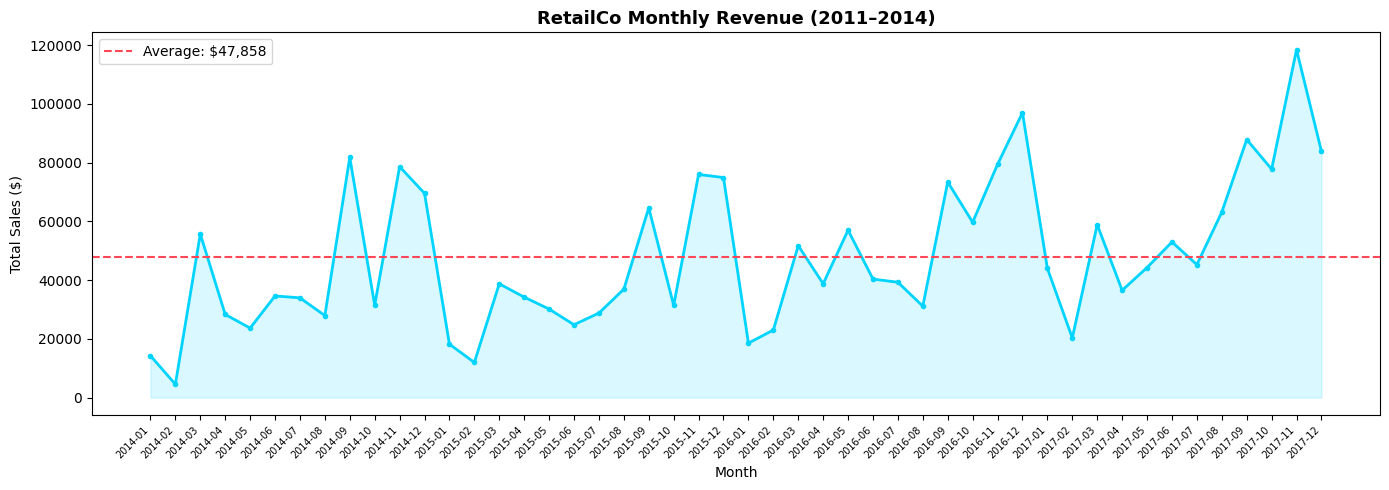

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/sumit0072/Superstore-Data-Analysis/main/Sample%20-%20Superstore.csv"
df = pd.read_csv(url, encoding="latin-1")

# Monthly sales trend - line chart
df["Order_Date"] = pd.to_datetime(df["Order Date"])
df["YearMonth"] = df["Order_Date"].dt.to_period("M")
monthly = df.groupby("YearMonth")["Sales"].sum().reset_index()
monthly["YearMonth"] = monthly["YearMonth"].astype(str)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly["YearMonth"],
    monthly["Sales"],
    color="#00d4ff",
    linewidth=2,
    marker="o",
    markersize=3,
)

plt.fill_between(
    monthly["YearMonth"],
    monthly["Sales"],
    alpha=0.15,
    color="#00d4ff",
)

avg = monthly["Sales"].mean()

plt.axhline(
    avg,
    color="#ff4757",
    linestyle="--",
    linewidth=1.5,
    label=f"Average: ${avg:,.0f}",
)

plt.title("RetailCo Monthly Revenue (2011–2014)", fontsize=13, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45, ha="right", fontsize=7)

plt.legend()
plt.tight_layout()
plt.show()

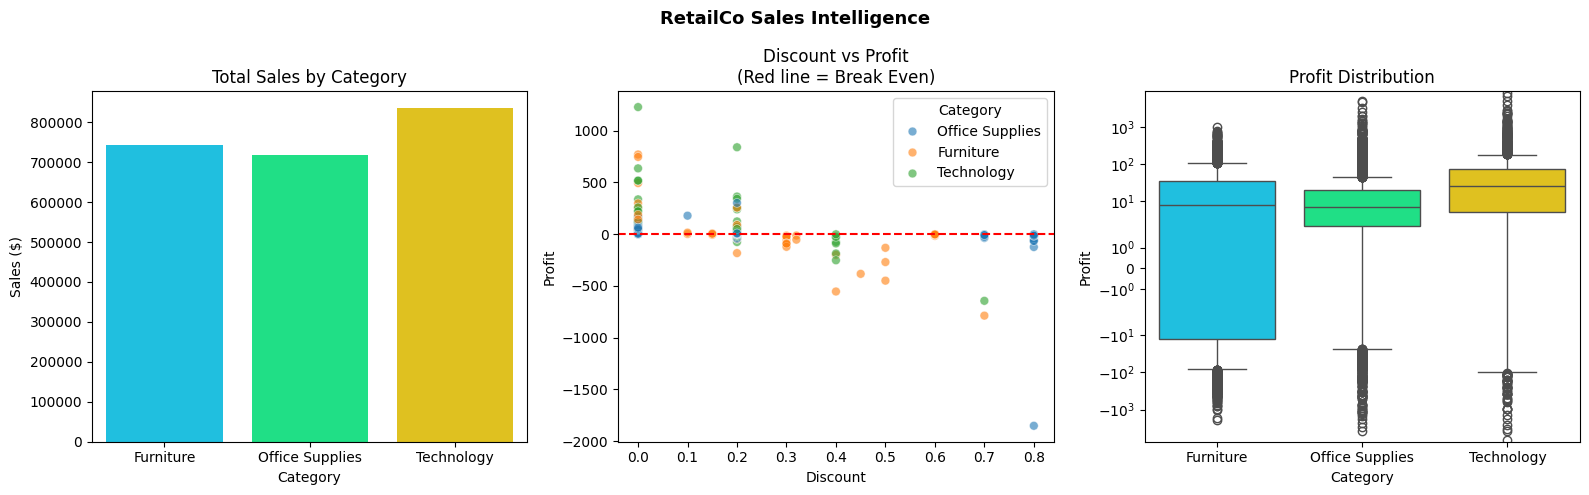

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("RetailCo Sales Intelligence", fontsize=13, fontweight="bold")

# ---------------------------
# Chart 1: Bar chart - Category Sales
# ---------------------------
cat = df.groupby("Category")["Sales"].sum().reset_index()   #For visualisation we need to reset_index

sns.barplot(
    data=cat,
    x="Category",
    y="Sales",
    ax=axes[0],
    hue="Category",
    palette=["#00d4ff", "#00ff88", "#ffd700"],
    legend=False
)

axes[0].set_title("Total Sales by Category")
axes[0].set_ylabel("Sales ($)")

# ---------------------------
# Chart 2: Scatter Plot - Discount vs Profit
# ---------------------------
sample = df.sample(500, random_state=42)

sns.scatterplot(
    data=sample,
    x="Discount",
    y="Profit",
    hue="Category",
    ax=axes[1],
    alpha=0.6,
    s=40
)

axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Discount vs Profit\n(Red line = Break Even)")

# ---------------------------
# Chart 3: Box Plot - Profit Distribution
# ---------------------------
sns.boxplot(
    data=df,
    x="Category",
    y="Profit",
    ax=axes[2],
    hue="Category",
    palette=["#00d4ff", "#00ff88", "#ffd700"],
    legend=False
)

axes[2].set_title("Profit Distribution")
axes[2].set_yscale("symlog")

plt.tight_layout()
plt.show()

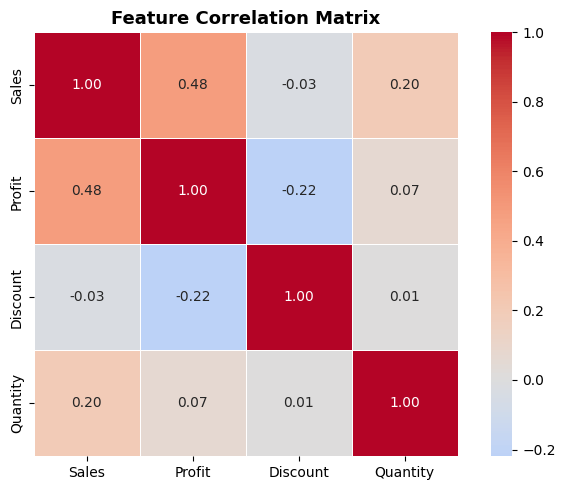

In [ ]:
#HeatMap - shows relationships between all numeric features at once
numeric = df[["Sales","Profit","Discount","Quantity"]].copy()
corr    = numeric.corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm",
            center=0,square=True,linewidth=0.5)
plt.title("Feature Correlation Matrix",fontsize=13,fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
print("KEY CORRELATIONS:")
print(f"Discount - Profit: {corr.loc['Discount' , 'Profit']:.3f}")
print(" -> Negative! Higher discount = LOWER profit")
print(f"\n Sales - Profit: {corr.loc['Sales', 'Profit']:.3f}")
print(" -> Positive but weak - big sales dont always mean big profit")

print("\n This is why data science beats intuition")
print("Every manager THINKS more discount = more sales = more profit")
print("The data says: more discount = LESS profit.")

KEY CORRELATIONS:
Discount - Profit: -0.219
 -> Negative! Higher discount = LOWER profit

 Sales - Profit: 0.479
 -> Positive but weak - big sales dont always mean big profit

 This is why data science beats intuition
Every manager THINKS more discount = more sales = more profit
The data says: more discount = LESS profit.


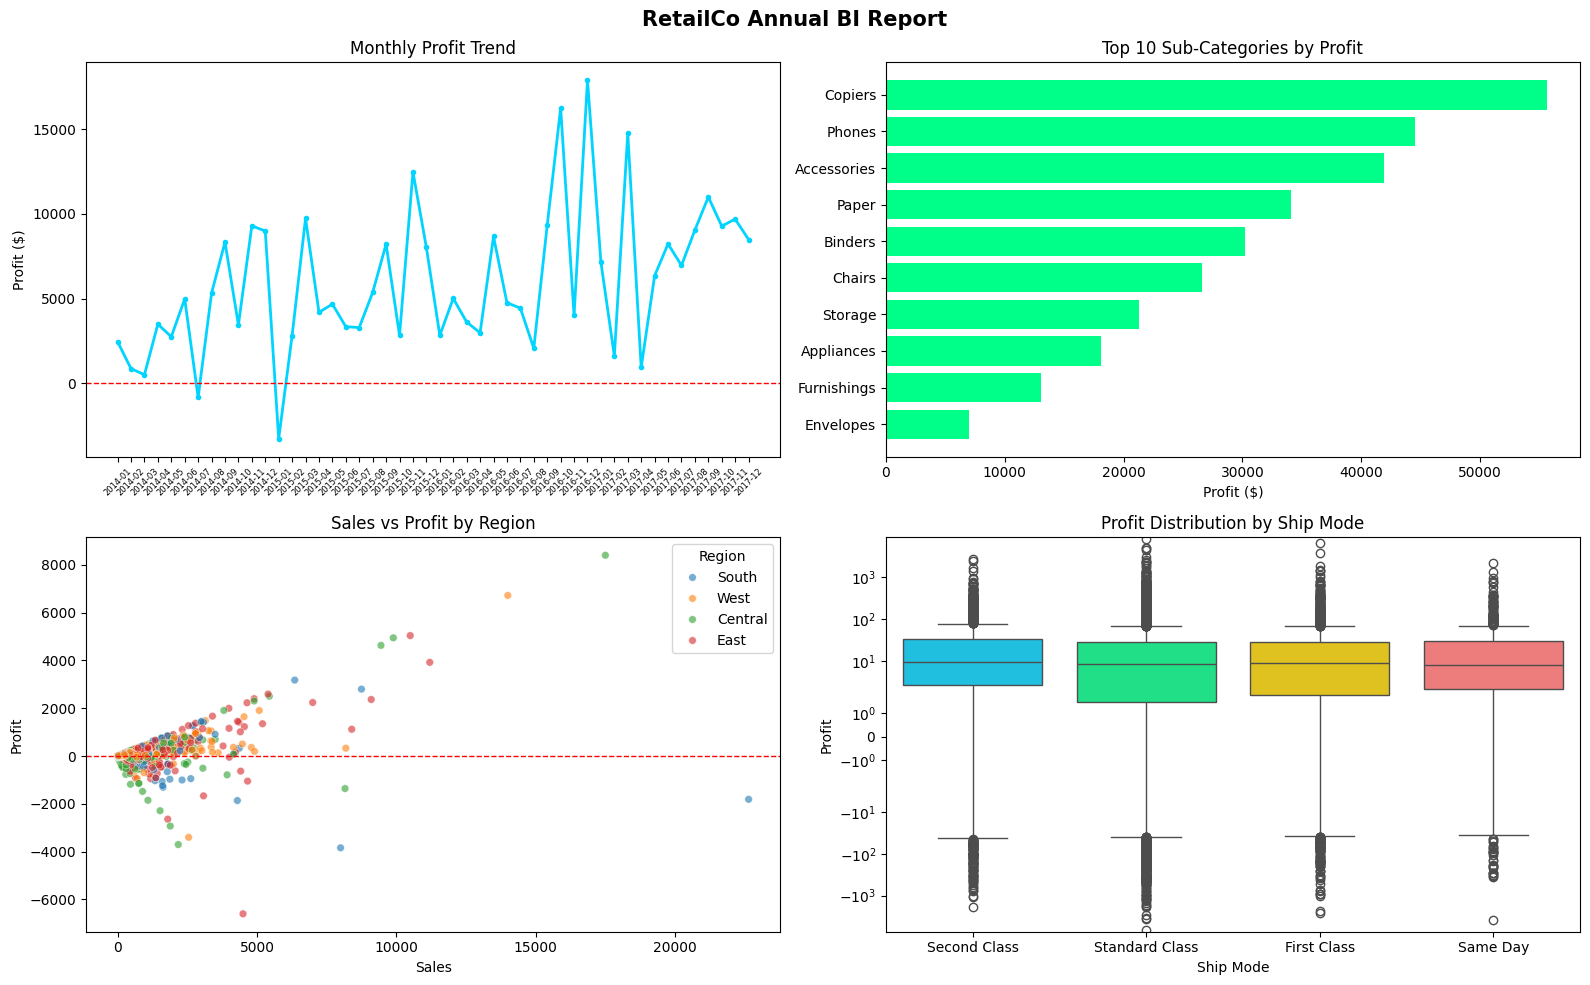

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("RetailCo Annual BI Report", fontsize=15, fontweight="bold")

# ── Chart 1: Monthly profit trend (line) ──────────────────────
df["Order_Date"] = pd.to_datetime(df["Order Date"])
df["YearMonth"] = df["Order_Date"].dt.to_period("M")
monthly_profit = df.groupby("YearMonth")["Profit"].sum().reset_index()
monthly_profit["YearMonth"] = monthly_profit["YearMonth"].astype(str)

axes[0, 0].plot(monthly_profit["YearMonth"], monthly_profit["Profit"],
                 color="#00d4ff", linewidth=2, marker="o", markersize=3)
axes[0, 0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0, 0].set_title("Monthly Profit Trend")
axes[0, 0].set_ylabel("Profit ($)")
axes[0, 0].tick_params(axis="x", rotation=45, labelsize=6)

# ── Chart 2: Top 10 Sub-Categories by profit (horizontal bar) ─
subcat_profit = (df.groupby("Sub-Category")["Profit"].sum()
                    .sort_values(ascending=False).head(10)
                    .sort_values())  # ascending so highest ends up at top of barh

axes[0, 1].barh(subcat_profit.index, subcat_profit.values, color="#00ff88")
axes[0, 1].set_title("Top 10 Sub-Categories by Profit")
axes[0, 1].set_xlabel("Profit ($)")

# ── Chart 3: Sales vs Profit scatter (color by Region) ────────
sns.scatterplot(data=df, x="Sales", y="Profit", hue="Region",
                 ax=axes[1, 0], alpha=0.6, s=30)
axes[1, 0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1, 0].set_title("Sales vs Profit by Region")

# ── Chart 4: Profit distribution by Ship Mode (box plot) ──────
sns.boxplot(data=df, x="Ship Mode", y="Profit", ax=axes[1, 1],
            hue="Ship Mode", palette=["#00d4ff","#00ff88","#ffd700","#ff6b6b"],
            legend=False)
axes[1, 1].set_title("Profit Distribution by Ship Mode")
axes[1, 1].set_yscale("symlog")

plt.tight_layout()
plt.show()

In [ ]:
#Chart 1: Monthly Profit Trend
#Profit goes up and down a lot every month, but if you squint, it's generally getting better over time. There's this one scary dip near the end of 2014 where we actually lost money, but after that it mostly bounces back stronger each year.
#Chart 2: Top 10 Sub-Categories by Profit
#Copiers make way more money than anything else, with Phones and Accessories not too far behind. Stuff like Envelopes and Furnishings barely make any profit compared to the top ones.
#Chart 3: Sales vs Profit by Region
#Most orders don't make or lose much money no matter which region they're from everything's kind of bunched near zero. But there are a few big outlier orders (especially in Central and West) that make a lot of profit, and one South order that lost a lot despite huge sales.
#Chart 4: Profit Distribution by Ship Mode
#The median profit is similar across all shipping modes, indicating that the typical profit does not vary significantly by shipping method. Standard Class and First Class show slightly greater variability in profits. All shipping modes contain numerous positive and negative outliers, suggesting the presence of both highly profitable and loss-making orders.